# Does Parakh's signal hold up? A SQL analysis of the track record

Parakh publishes a weekly lean on 20 NIFTY 50 stocks: will this stock **beat the NIFTY 50 over the next 5 trading days?**
This notebook checks the model's walk-forward track record with six SQL queries run directly against the production Postgres database (Neon).

| # | Question | Section |
|---|---|---|
| 1 | Is the hit rate stable over time, or did a few years carry it? | Stability |
| 2 | Do "Stronger edge" calls hit more often, and are the probabilities calibrated? | Confidence |
| 3 | Which stocks does it work on, and how sure can we be? | Per stock |
| 4 | Does it work better when the market is rising or falling? | Market regime |
| 5 | After trading costs, is it worth acting on? | Business answer |
| 6 | Can the underlying data be trusted? | Data quality |

**Data.** `backtest_predictions` holds one row per stock per trading day from 2019 to Oct 2026, scored by the active model (the reversal rule, [D-024](../docs/decisions.md)). 2019–24 are the research years and 2025–26 is the holdout, kept unseen until the final test ([D-022](../docs/decisions.md)). `prices` holds daily OHLCV data back to 2016. The live ledger (`predictions`, `outcomes`) started on 22 Oct 2026 and has too few scored calls to analyse yet.

**One caution throughout.** Each call covers 5 trading days, so calls on neighbouring days for the same stock share most of their outcome. Raw counts therefore overstate how much independent evidence there is. Where a confidence interval is shown, it uses an effective sample size of n / 5.

## Key findings

1. **Not stable.** The hit rate ranged from 50.2% to 55.1% across the research years, then fell to 44.2% in 2026. The holdout as a whole came in at 48.8%, below a coin flip.
2. **Confidence labels don't sort calls.** "Stronger edge" calls hit *less* often than "Slight edge" calls (50.9% vs 51.8%), and the top probability decile beat the index less often than the middle deciles.
3. **No stock is reliably good.** Every stock's 95% interval includes or touches 50%, so the per-stock ranking is mostly noise.
4. **Bearish leans did the work.** Bearish calls hit about 53% in both rising and falling markets. Bullish calls hit about 50%.
5. **Not worth trading.** The average call returned +0.07% relative to the index, while a round trip costs about 0.25%. Only 39% of months cleared that cost.
6. **Stock data is clean; the index has gaps.** No stock is missing a trading day and no price is impossible. The NIFTY 50 series is missing a few trading days, though, and one holiday has placeholder stock rows. The pipeline doesn't catch either.

The conclusion matches the [model card](../docs/model-card.md): the edge is too small and too unstable to act on. The product therefore leads with honesty about the record, not with accuracy.

## Setup

A read-only connection, so nothing in this notebook can change the ledger. `sql()` runs a query and returns a DataFrame.

In [1]:
import sys
from decimal import Decimal
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import psycopg

sys.path.insert(0, str(Path.cwd().parent))  # run from analysis/
from ledger.db import database_url

conn = psycopg.connect(database_url())
conn.read_only = True

def sql(query: str) -> pd.DataFrame:
    cur = conn.execute(query)
    df = pd.DataFrame(cur.fetchall(), columns=[d.name for d in cur.description])
    decimals = [c for c in df if df[c].map(lambda v: isinstance(v, Decimal)).any()]
    return df.astype({c: float for c in decimals})  # Postgres NUMERIC arrives as Decimal

BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#8a8984", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "font.size": 10,
})

sql("SELECT version, kind, trained_through FROM model_versions WHERE is_active")

,version,kind,trained_through
0,reversal-20261014,reversal,2026-10-14


Every query below starts from the same CTE, `calls`. It keeps only days with a lean (bullish or bearish) and adds two derived columns:

- `hit`: was the lean right? A bullish lean is right when the stock beat the index. A bearish lean is right when it didn't.
- `dir_excess`: the return relative to the index *in the direction of the lean*, so a positive number means the call made money before costs.

In [2]:
CALLS = """
calls AS (
    SELECT ticker, date, lean, confidence, p_outperform, excess_return,
           CASE WHEN lean = 'bullish' THEN excess_return ELSE -excess_return END AS dir_excess,
           (lean = 'bullish') = beat_index                                      AS hit
    FROM backtest_predictions
    WHERE lean <> 'no_call'
)"""

sql("""
SELECT lean, count(*) AS days, round(100.0 * count(*) / sum(count(*)) OVER (), 1) AS pct
FROM backtest_predictions GROUP BY lean ORDER BY days DESC
""")

,lean,days,pct
0,no_call,28482,74.2
1,bearish,5113,13.3
2,bullish,4804,12.5


Parakh says **No call on 74% of stock-days**: a lean is only published when the signal clears a threshold. The rest of the analysis is about the 9,917 calls it did make.

## 1. Is the hit rate stable over time?

Hit rate and average directional excess return by year, labelled research or holdout.

In [3]:
by_year = sql(f"""
WITH {CALLS}
SELECT extract(year FROM date)::int                                          AS year,
       CASE WHEN date < '2025-01-01' THEN 'research' ELSE 'holdout' END       AS period,
       count(*)                                                              AS calls,
       round(avg(hit::int), 3)                                               AS hit_rate,
       round(100 * avg(dir_excess)::numeric, 3)                              AS avg_dir_excess_pct
FROM calls
GROUP BY 1, 2
ORDER BY 1
""")
by_year

,year,period,calls,hit_rate,avg_dir_excess_pct
0,2019,research,1241,0.525,0.134
1,2020,research,1391,0.528,0.187
2,2021,research,1262,0.505,-0.047
3,2022,research,1293,0.551,0.371
4,2023,research,1268,0.502,0.132
5,2024,research,1276,0.516,0.076
6,2025,holdout,1230,0.523,0.074
7,2026,holdout,956,0.442,-0.332


To see how noisy a single year's number is, here is a rolling one-year (250 trading-day) hit rate. It is a window function over daily totals, weighted by the number of calls each day.

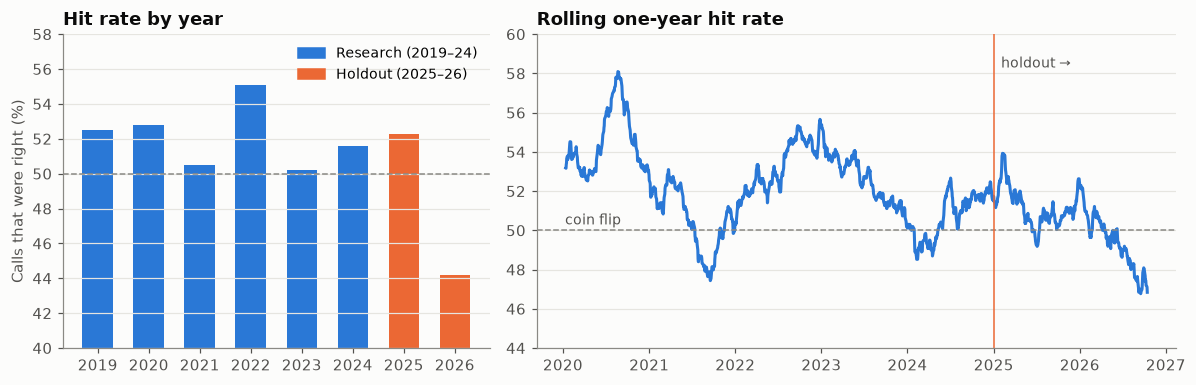

In [4]:
rolling = sql(f"""
WITH {CALLS},
daily AS (
    SELECT date, sum(hit::int) AS hits, count(*) AS n
    FROM calls GROUP BY date
)
SELECT date,
       sum(hits) OVER w::float8 / sum(n) OVER w AS rolling_hit_rate,
       count(*)  OVER w                         AS days_in_window
FROM daily
WINDOW w AS (ORDER BY date ROWS BETWEEN 249 PRECEDING AND CURRENT ROW)
ORDER BY date
""").query("days_in_window == 250")

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.5]})
colors = [BLUE if p == "research" else ORANGE for p in by_year.period]
a.bar(by_year.year.astype(str), by_year.hit_rate * 100, color=colors, width=0.6)
a.axhline(50, color=GREY, lw=1, ls="--")
a.set_ylim(40, 58); a.set_ylabel("Calls that were right (%)")
a.set_title("Hit rate by year")
a.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
         labels=["Research (2019–24)", "Holdout (2025–26)"], frameon=False, loc="upper right", fontsize=9)

b.plot(pd.to_datetime(rolling.date), rolling.rolling_hit_rate * 100, color=BLUE, lw=2)
b.axhline(50, color=GREY, lw=1, ls="--"); b.text(pd.Timestamp("2020-01-10"), 50.3, "coin flip", color=MUTED, fontsize=9)
b.axvline(pd.Timestamp("2025-01-01"), color=ORANGE, lw=1); b.text(pd.Timestamp("2025-02-01"), 58.3, "holdout →", color=MUTED, fontsize=9)
b.set_ylim(44, 60); b.set_title("Rolling one-year hit rate")
fig.tight_layout(); plt.show()

**What this says.** Every research year was above 50%, but only one (2022) was clearly so, and 2021 and 2023 were barely above a coin flip. The rolling line spends most of its time between 50% and 54%, then drops below 50% through 2026. The 2026 collapse (44.2%) is what pulled the holdout to 48.8%. A single good year would not have shown this. The signal's edge is small, and it doesn't persist.

## 2. Do confident calls hit more often?

The app labels each call *Slight edge* or *Stronger edge*. If the labels mean anything, Stronger edge calls should hit more often. `ROLLUP` adds subtotals per label and a grand total.

In [5]:
sql(f"""
WITH {CALLS}
SELECT coalesce(confidence, 'All calls')   AS confidence,
       coalesce(lean, 'all')               AS lean,
       count(*)                            AS calls,
       round(avg(hit::int), 3)             AS hit_rate,
       round(100 * avg(dir_excess)::numeric, 3) AS avg_dir_excess_pct
FROM calls
GROUP BY ROLLUP (confidence, lean)
ORDER BY confidence NULLS LAST, lean NULLS LAST
""")

,confidence,lean,calls,hit_rate,avg_dir_excess_pct
0,All calls,all,9917,0.514,0.089
1,Slight edge,all,5004,0.518,0.080
2,Slight edge,bearish,2349,0.541,0.110
3,Slight edge,bullish,2655,0.498,0.053
4,Stronger edge,all,4913,0.509,0.098
5,Stronger edge,bearish,2764,0.526,0.077
6,Stronger edge,bullish,2149,0.489,0.126


A sharper version of the same question is calibration. Split **every** stock-day into ten equal groups (deciles) by the model's probability, then compare the average predicted probability with how often the stock actually beat the index.

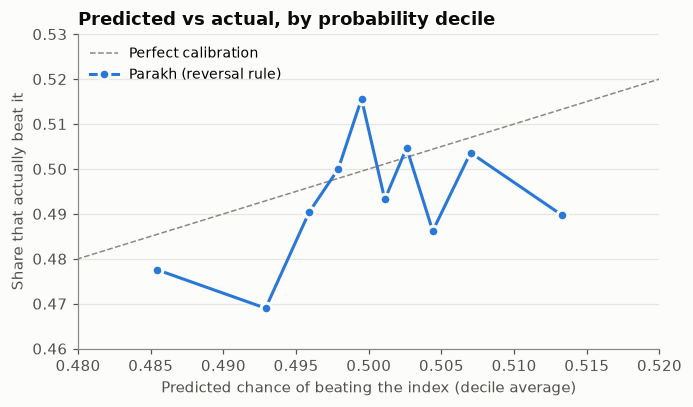

,decile,days,predicted,actual
0,1,3840,0.4854,0.4776
1,2,3840,0.4929,0.4690
2,3,3840,0.4959,0.4904
3,4,3840,0.4979,0.5000
4,5,3840,0.4995,0.5156
5,6,3840,0.5011,0.4932
6,7,3840,0.5026,0.5047
7,8,3840,0.5044,0.4862
8,9,3840,0.5070,0.5036
9,10,3839,0.5133,0.4897


In [6]:
calib = sql("""
WITH ranked AS (
    SELECT p_outperform, beat_index, ntile(10) OVER (ORDER BY p_outperform) AS decile
    FROM backtest_predictions
)
SELECT decile,
       count(*)                          AS days,
       round(avg(p_outperform)::numeric, 4)   AS predicted,
       round(avg(beat_index::int), 4)    AS actual
FROM ranked GROUP BY decile ORDER BY decile
""")

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot([0.47, 0.53], [0.47, 0.53], color=GREY, lw=1, ls="--", label="Perfect calibration")
ax.plot(calib.predicted, calib.actual, color=BLUE, lw=2, marker="o", ms=7, mec="#fcfcfb", mew=2, label="Parakh (reversal rule)")
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.set_xlim(0.48, 0.52); ax.set_ylim(0.46, 0.53)
ax.set_xlabel("Predicted chance of beating the index (decile average)")
ax.set_ylabel("Share that actually beat it")
ax.set_title("Predicted vs actual, by probability decile")
fig.tight_layout(); plt.show()
calib

**What this says.** The labels don't sort calls. Stronger edge calls hit 50.9% of the time and Slight edge calls 51.8%. The calibration chart shows why: the predicted probabilities sit in a narrow band (48.5% to 51.3%), and the actual beat rate zig-zags around 49–51% with no upward slope. The top decile, where the model was most bullish, beat the index only 49.0% of the time. Calibration error is small in absolute terms only because every prediction is close to 50%.

**Product implication:** "Stronger edge" claims more than the data supports. Merging the two labels, or renaming them to something like "Lean" and "Stronger lean, not more accurate in testing", would be more honest.

## 3. Which stocks does it work on?

Hit rate per stock, with a 95% **Wilson interval** computed in SQL. Overlapping 5-day windows mean consecutive calls on a stock aren't independent, so the interval uses `n_eff = n / 5`.

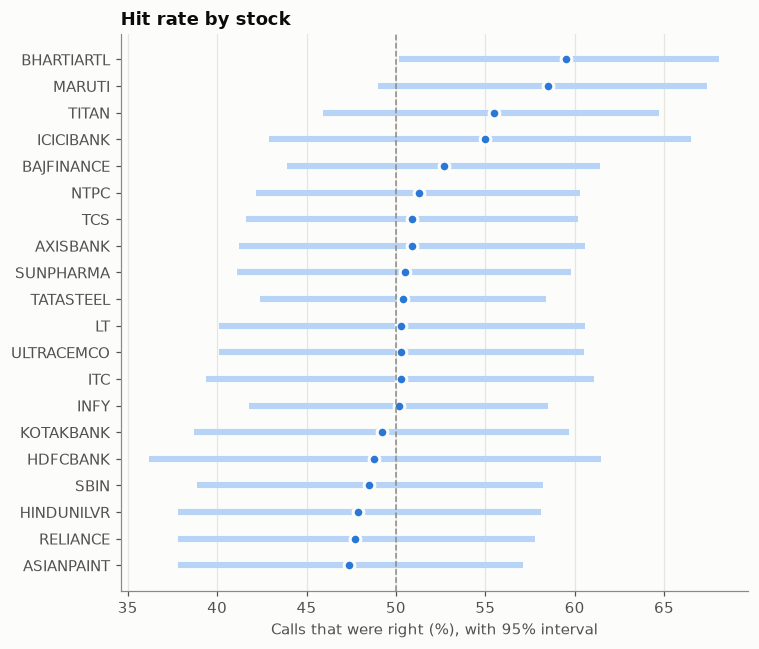

,stock,calls,hit_rate,ci_low,ci_high,avg_dir_excess_pct
0,BHARTIARTL,555,0.595,0.502,0.681,0.572
1,MARUTI,530,0.585,0.490,0.674,0.699
2,TITAN,519,0.555,0.459,0.647,0.308
3,ICICIBANK,322,0.550,0.429,0.665,0.245
4,BAJFINANCE,605,0.527,0.439,0.614,-0.074
5,NTPC,569,0.513,0.422,0.603,-0.076
6,TCS,540,0.509,0.416,0.602,0.094
7,AXISBANK,489,0.509,0.412,0.606,0.174
8,SUNPHARMA,531,0.505,0.411,0.598,0.060
9,TATASTEEL,732,0.504,0.424,0.584,-0.121


In [7]:
per_stock = sql(f"""
WITH {CALLS},
s AS (
    SELECT replace(ticker, '.NS', '') AS stock,
           count(*)                   AS calls,
           avg(hit::int)::float8      AS p,
           100 * avg(dir_excess)      AS avg_dir_excess_pct
    FROM calls GROUP BY 1
),
w AS (SELECT *, calls / 5.0 AS n, 1.96 AS z FROM s)
SELECT stock, calls,
       round(p::numeric, 3) AS hit_rate,
       round(((p + z*z/(2*n) - z*sqrt(p*(1-p)/n + z*z/(4*n*n))) / (1 + z*z/n))::numeric, 3) AS ci_low,
       round(((p + z*z/(2*n) + z*sqrt(p*(1-p)/n + z*z/(4*n*n))) / (1 + z*z/n))::numeric, 3) AS ci_high,
       round(avg_dir_excess_pct::numeric, 3) AS avg_dir_excess_pct
FROM w
ORDER BY p DESC
""")

d = per_stock.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.hlines(d.stock, d.ci_low * 100, d.ci_high * 100, color="#b7d3f6", lw=4)
ax.plot(d.hit_rate * 100, d.stock, "o", color=BLUE, ms=7, mec="#fcfcfb", mew=2)
ax.axvline(50, color=GREY, lw=1, ls="--")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Calls that were right (%), with 95% interval")
ax.set_title("Hit rate by stock")
fig.tight_layout(); plt.show()
per_stock

**What this says.** The ranking looks meaningful (BHARTIARTL 59.5%, ASIANPAINT 47.4%), but the intervals are about ±9 points wide, and only BHARTIARTL's lower bound clears 50%, by 0.2 points. With 20 stocks tested, one borderline result is what chance alone would produce. A per-stock list of "where the model works" shouldn't be shown as a finding, which is why the app shows a range next to each stock's warning instead of a verdict.

## 4. Does it depend on the market regime?

Each call is tagged by whether the NIFTY 50 closed above or below its 50-day average **on the call date**. The window function uses only past prices, so there is no look-ahead: the regime is something a user could have known at the time.

In [8]:
sql(f"""
WITH {CALLS},
nifty AS (
    SELECT date, close,
           avg(close) OVER (ORDER BY date ROWS BETWEEN 49 PRECEDING AND CURRENT ROW) AS ma50
    FROM prices WHERE ticker = '^NSEI'
)
SELECT coalesce(CASE WHEN n.close > n.ma50 THEN 'uptrend' ELSE 'downtrend' END, 'all') AS regime,
       coalesce(c.lean, 'all')                    AS lean,
       count(*)                                   AS calls,
       round(avg(c.hit::int), 3)                  AS hit_rate,
       round(100 * avg(c.dir_excess)::numeric, 3) AS avg_dir_excess_pct
FROM calls c JOIN nifty n USING (date)
GROUP BY ROLLUP (CASE WHEN n.close > n.ma50 THEN 'uptrend' ELSE 'downtrend' END, c.lean)
ORDER BY 1, 2
""")

,regime,lean,calls,hit_rate,avg_dir_excess_pct
0,all,all,9917,0.514,0.089
1,downtrend,all,3573,0.514,0.025
2,downtrend,bearish,1809,0.528,0.041
3,downtrend,bullish,1764,0.501,0.008
4,uptrend,all,6344,0.514,0.126
5,uptrend,bearish,3304,0.535,0.120
6,uptrend,bullish,3040,0.490,0.131


**What this says.** The overall hit rate is identical in both regimes (51.4%), but the lean matters. **Bearish calls hit about 53%** in both regimes (52.8% and 53.5%), while bullish calls hit about 50% (50.1% and 49.0%). The reversal rule works better at flagging last week's winners that will lag than last week's losers that will rebound. Uptrends gave larger directional returns per call (+0.13% vs +0.03%), even though the hit rate was the same.

This is a hypothesis, not a result. The research rules in D-022 fixed the experiments in advance, so a "bearish only" variant would need a fresh holdout before it could be trusted.

## 5. Is it worth acting on after costs?

A round trip (buy and sell) costs about **0.25%** in brokerage, taxes and spread. The question is how often the average call in a month would have cleared that cost.

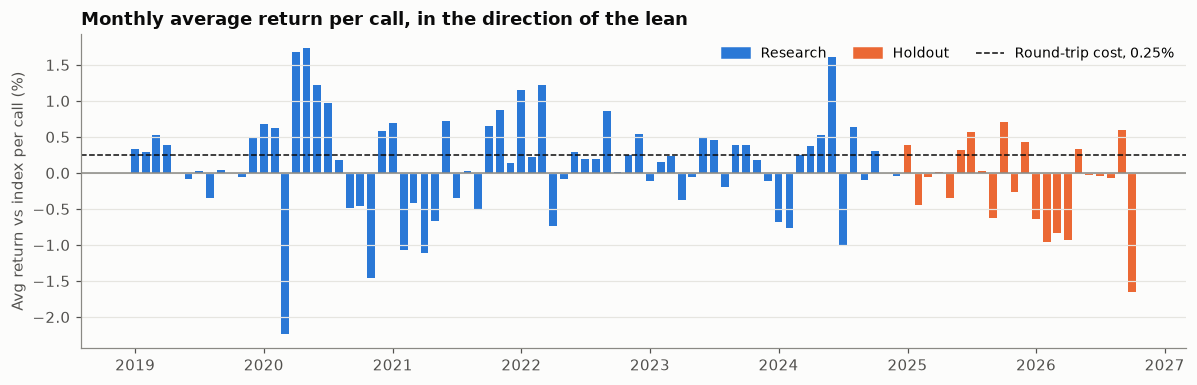

,months,avg_monthly_dir_excess_pct,median_pct,share_months_positive,share_months_beating_cost
0,94,0.072,0.092,0.564,0.394


In [9]:
monthly = sql(f"""
WITH {CALLS}
SELECT date_trunc('month', date)::date AS month,
       count(*)                        AS calls,
       avg(dir_excess)::float8         AS avg_dir_excess
FROM calls GROUP BY 1 ORDER BY 1
""")

summary = sql(f"""
WITH {CALLS},
m AS (SELECT date_trunc('month', date) AS month, avg(dir_excess) AS dx FROM calls GROUP BY 1)
SELECT count(*)                                                   AS months,
       round(100 * avg(dx)::numeric, 3)                           AS avg_monthly_dir_excess_pct,
       round(100 * percentile_cont(0.5) WITHIN GROUP (ORDER BY dx)::numeric, 3) AS median_pct,
       round(avg((dx > 0)::int), 3)                               AS share_months_positive,
       round(avg((dx > 0.0025)::int), 3)                          AS share_months_beating_cost
FROM m
""")

fig, ax = plt.subplots(figsize=(11, 3.6))
m = pd.to_datetime(monthly.month)
ax.bar(m, monthly.avg_dir_excess * 100, width=22, color=[BLUE if d < pd.Timestamp("2025-01-01") else ORANGE for d in m])
ax.axhline(0, color=GREY, lw=1)
cost = ax.axhline(0.25, color=INK, lw=1, ls="--")
ax.set_ylabel("Avg return vs index per call (%)")
ax.set_title("Monthly average return per call, in the direction of the lean")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE), cost],
          labels=["Research", "Holdout", "Round-trip cost, 0.25%"], frameon=False, loc="upper right", ncol=3, fontsize=9)
fig.tight_layout(); plt.show()
summary

**What this says.** The average call earned **+0.07%** relative to the index over its 5 days. That is positive in 56% of months, but it cleared the 0.25% cost in only **39% of months**. Bar size is dominated by noise, and no run of months reliably clears the line. This is the business answer: even taken at face value, the edge wouldn't survive costs, so Parakh is presented as a way to judge sources, not a trading signal.

## 6. Can the data be trusted?

Three checks on the `prices` table for the 20 stocks:

- **Missing days:** NIFTY 50 trading days (between each stock's first and last row) with no row for that stock.
- **Extra days:** stock rows on days the index didn't trade.
- **Impossible prices:** a high below the low, or an open or close outside the day's range, plus rows with zero volume.

In [10]:
sql("""
WITH cal AS (SELECT date FROM prices WHERE ticker = '^NSEI'),
universe AS (SELECT DISTINCT ticker FROM backtest_predictions),
span AS (
    SELECT p.ticker, min(date) AS first_day, max(date) AS last_day, count(*) AS rows
    FROM prices p JOIN universe USING (ticker) GROUP BY 1
),
missing AS (
    SELECT s.ticker, count(*) AS missing_days
    FROM span s
    JOIN cal ON cal.date BETWEEN s.first_day AND s.last_day
    LEFT JOIN prices p ON p.ticker = s.ticker AND p.date = cal.date
    WHERE p.ticker IS NULL
    GROUP BY 1
),
extra AS (
    SELECT p.ticker, count(*) AS extra_days
    FROM prices p JOIN universe USING (ticker) LEFT JOIN cal USING (date)
    WHERE cal.date IS NULL GROUP BY 1
),
sanity AS (
    SELECT ticker,
           count(*) FILTER (WHERE high < low OR open > high OR open < low OR close > high OR close < low) AS bad_ohlc,
           count(*) FILTER (WHERE volume IS NULL OR volume = 0)                                          AS zero_volume
    FROM prices GROUP BY 1
)
SELECT count(*)                         AS stocks,
       min(first_day)                   AS first_day,
       max(last_day)                    AS last_day,
       sum(coalesce(missing_days, 0))::int AS missing_days,
       sum(coalesce(extra_days, 0))::int   AS extra_rows,
       sum(bad_ohlc)::int                  AS impossible_prices,
       sum(zero_volume)::int               AS zero_volume_rows
FROM span LEFT JOIN missing USING (ticker) LEFT JOIN extra USING (ticker) JOIN sanity USING (ticker)
""")

,stocks,first_day,last_day,missing_days,extra_rows,impossible_prices,zero_volume_rows
0,20,2016-01-01,2026-10-23,0,140,0,39


No missing days and no impossible prices. The extra rows and zero-volume rows need a closer look:

In [11]:
sql("""
SELECT p.date,
       to_char(p.date, 'Dy')                           AS weekday,
       count(*)                                        AS stocks_with_a_row,
       count(*) FILTER (WHERE p.volume = 0)            AS with_zero_volume,
       EXISTS (SELECT 1 FROM backtest_predictions b WHERE b.date = p.date) AS used_for_calls
FROM prices p
WHERE p.ticker IN (SELECT DISTINCT ticker FROM backtest_predictions)
  AND NOT EXISTS (SELECT 1 FROM prices i WHERE i.ticker = '^NSEI' AND i.date = p.date)
GROUP BY p.date ORDER BY p.date
""")

,date,weekday,stocks_with_a_row,with_zero_volume,used_for_calls
0,2016-01-01,Fri,20,0,False
1,2016-08-12,Fri,20,0,False
2,2018-01-01,Mon,20,0,False
3,2019-01-01,Tue,20,0,False
4,2019-10-27,Sun,20,0,False
5,2020-11-14,Sat,20,0,False
6,2026-01-15,Thu,20,20,False


The 140 extra rows are 20 stocks on **7 dates with no NIFTY 50 row**. There are three different causes:

- **The index is missing on real trading days.** On 1 Jan 2018, 1 Jan 2019 and 12 Aug 2016, the stocks traded normally with real volume, but Yahoo Finance has no index row. 1 Jan 2016 is just before the index series starts.
- **Muhurat trading.** Sun 27 Oct 2019 and Sat 14 Nov 2020 were the one-hour Diwali sessions. The stock rows are genuine, but the index wasn't recorded.
- **A placeholder row on a holiday.** On 15 Jan 2026 every stock has a flat row with zero volume. The market was closed and the feed filled the day in anyway.

The other 19 zero-volume rows all fall on **18 Mar 2025**, a normal trading day: 19 of the 20 stocks show zero volume, which is a feed glitch, not a real quiet day.

No calls were made on any of these dates, but the rows still sit inside the rolling windows used to build features. Volume z-scores see a zero, and a "5-day" window can cover a different span for a stock than for the index.

**Recommended fix:** at load time in `ml/data.py`, check every stock against an exchange holiday calendar, drop placeholder rows and treat zero volume as missing, and flag missing index days instead of silently skipping them. Under the research rules this belongs in the next retrain, not a silent change now.

Finally, pipeline reliability. Every job run is logged, so gaps in the live ledger can be explained.

In [12]:
sql("""
SELECT job, status, count(*) AS runs, min(started_at)::date AS first_run, max(started_at)::date AS last_run
FROM job_runs GROUP BY 1, 2 ORDER BY 1
""")

,job,status,runs,first_run,last_run
0,daily,ok,8,2026-10-21,2026-10-23
1,retrain,ok,2,2026-10-21,2026-10-22


## What I'd do next

- **Merge or relabel the confidence tiers** (section 2). This is the clearest product change the data supports.
- **Filter the price feed to the trading calendar** at the next retrain (section 6).
- **Pre-register a bearish-only variant** and test it on data the model hasn't seen yet (section 4). Don't pick it based on these results.
- **Rerun sections 1, 2 and 5 on the live `outcomes` table** once a few hundred live calls are scored, and check that the live hit rate falls inside the backtest's range.

In [13]:
conn.close()